# Проект: интеллектуальная защита картографических сервисов от несанкционированного скачивания

Пайплайн:
1. Экспорт логов из OpenSearch
2. Объединение и разметка (clean / synthetic)
3. Построение окон и признаков
4. Сравнение моделей anomaly detection
5. Перебор гиперпараметров + кривые обучения
6. Сохранение артефакта модели

In [137]:
from __future__ import annotations
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

## 1. Объединение и разметка (clean / synthetic)

Читаем файлы json

In [138]:
import json
import pandas as pd

files = [
    ("tmp_files/requests_raw_clean.json", "clean"),
    ("tmp_files/requests_raw_synthetic.json", "synthetic"),
]

out = r"tmp_files/requests_merged_labeled.csv"
rows = []

for path, label in files:
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for item in data:
        s = item.get("_source", item)
        rows.append({
            "requestTime": s.get("requestTime"),
            "userIp": s.get("userIp"),
            "x": s.get("x"),
            "y": s.get("y"),
            "z": s.get("z"),
            "sourceLabel": label,
        })



Собираем в датафрейм и чистим

In [139]:
df = pd.DataFrame(rows)
df["requestTime"] = pd.to_datetime(df["requestTime"], errors="coerce", utc=True)
for c in ["x", "y", "z"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.sort_values(["userIp", "requestTime"]).reset_index(drop=True)
df["sessionId"] = df["requestTime"].dt.floor("1h").astype(str)
df.to_csv(out, index=False)

print("Сохранено как :", out)
print("Строк:", len(df))
print(df["sourceLabel"].value_counts().to_string())


Сохранено как : tmp_files/requests_merged_labeled.csv
Строк: 11014
sourceLabel
synthetic    5800
clean        5214


# 2. Построение окон и признаков

Обозначим признаки и построким 30 окон с шагом 5

In [140]:
WINDOW = 30
STEP = 30



Сгруппируем запросы в сессии 

Построим окна

In [141]:
def build_windows(df_in: pd.DataFrame, window: int, step: int) -> pd.DataFrame:
    df_in = df_in.copy()
    df_in["groupId"] = df_in["userIp"].astype(str)
    rows = []

    for _, g in df_in.groupby("groupId"):
        g = g.sort_values("requestTime").reset_index(drop=True)
        if len(g) < window:
            continue

        for i in range(0, len(g) - window + 1, step):
            w = g.iloc[i:i+window]
            x = w["x"].to_numpy()
            y = w["y"].to_numpy()
            z = w["z"].to_numpy()
            t = w["requestTime"].astype("int64").to_numpy() / 1e9

            dx = np.diff(x)
            dy = np.diff(y)
            dt = np.diff(t)
            dt = np.where(dt <= 0, 1e-6, dt)

            rows.append({
                "groupId": w["groupId"].iloc[0],
                "startTime": w["requestTime"].iloc[0],
                "endTime": w["requestTime"].iloc[-1],
                "sourceLabel": w["sourceLabel"].mode().iloc[0],
                "req_count": len(w),
                "x_std": float(np.std(x)), "y_std": float(np.std(y)), "z_std": float(np.std(z)),
                "x_unique": int(len(np.unique(x))), "y_unique": int(len(np.unique(y))), "z_unique": int(len(np.unique(z))),
                "mean_abs_dx": float(np.mean(np.abs(dx))) if len(dx) else 0.0,
                "mean_abs_dy": float(np.mean(np.abs(dy))) if len(dy) else 0.0,
                "mean_dt": float(np.mean(dt)) if len(dt) else 0.0,
                "std_dt": float(np.std(dt)) if len(dt) else 0.0,
                "min_dt": float(np.min(dt)) if len(dt) else 0.0,
                "max_dt": float(np.max(dt)) if len(dt) else 0.0,
            })
    return pd.DataFrame(rows)

In [142]:
# Запускаем построение окон
wdf = build_windows(df, window=WINDOW, step=STEP)
wdf.to_csv("tmp_files/windows_features.csv", index=False)

print("Всего окон:", len(wdf))
print("Уникальных групп:", wdf["groupId"].nunique())
print(wdf["sourceLabel"].value_counts().to_string())

Всего окон: 365
Уникальных групп: 4
sourceLabel
synthetic    193
clean        172


# 4. Сравнение моделей anomaly detection

Явно задаем признаки и загружаем данные

In [143]:
FEATURE_COLS = [
    "req_count", "x_std", "y_std", "z_std",
    "x_unique", "y_unique", "z_unique",
    "mean_abs_dx", "mean_abs_dy",
    "mean_dt", "std_dt", "min_dt", "max_dt"
]

Инициализируем модели

In [144]:
df = pd.read_csv("tmp_files/windows_features.csv")
X = df[FEATURE_COLS].to_numpy()
y = (df["sourceLabel"] == "synthetic").astype(int).to_numpy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


models = {
    "Isolation Forest": IsolationForest(n_estimators=500, contamination=0.2, random_state=42),
    "One-Class SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("ocsvm", OneClassSVM(kernel="rbf", nu=0.3, gamma="scale"))
    ]),
    "LOF": Pipeline([
        ("scaler", StandardScaler()),
        ("lof", LocalOutlierFactor(n_neighbors=35, contamination=0.3, novelty=True))
    ])
}

wdf = pd.read_csv("tmp_files/windows_features.csv")
X = wdf[FEATURE_COLS].to_numpy()
y = (wdf["sourceLabel"] == "synthetic").astype(int).to_numpy()


Проводим кросс-валидацию

In [145]:
from sklearn.metrics import auc

results = []
plot_data = {name: {"y_true": [], "scores": []} for name in models.keys()}

for model_name, model in models.items():
    print(f"Кросс-валидация: {model_name}...")
    p_scores, r_scores, f1_scores, roc_scores, pr_scores = [], [], [], [], []
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        if len(np.unique(y_test)) < 2:continue
        X_train_clean = X_train[y_train == 0]
        model.fit(X_train_clean)
        y_pred = (model.predict(X_test) == -1).astype(int)
        if hasattr(model, "decision_function"):
            anomaly_scores = -model.decision_function(X_test)
        else:
            anomaly_scores = -model.score_samples(X_test)
            
        p_scores.append(precision_score(y_test, y_pred, zero_division=0))
        r_scores.append(recall_score(y_test, y_pred, zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
        roc_scores.append(roc_auc_score(y_test, anomaly_scores))
        pr_scores.append(average_precision_score(y_test, anomaly_scores))
        
        plot_data[model_name]["y_true"].extend(y_test)
        plot_data[model_name]["scores"].extend(anomaly_scores)

    results.append({
        "Модель": model_name,
        "Precision": f"{np.mean(p_scores):.2f} ± {np.std(p_scores):.2f}",
        "Recall": f"{np.mean(r_scores):.2f} ± {np.std(r_scores):.2f}",
        "F1": f"{np.mean(f1_scores):.2f} ± {np.std(f1_scores):.2f}",
        "ROC-AUC": f"{np.mean(roc_scores):.2f} ± {np.std(roc_scores):.2f}",
        "PR-AUC": f"{np.mean(pr_scores):.2f} ± {np.std(pr_scores):.2f}",
    })

Кросс-валидация: Isolation Forest...
Кросс-валидация: One-Class SVM (RBF)...
Кросс-валидация: LOF...


Отображаем результаты

In [146]:
df_results = pd.DataFrame(results)
display(df_results)
df_results.to_csv("tmp_files/model_compare_cv.csv", index=False)

,Модель,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Isolation Forest,0.84 ± 0.07,0.85 ± 0.16,0.83 ± 0.08,0.84 ± 0.07,0.77 ± 0.09
1,One-Class SVM (RBF),0.78 ± 0.05,0.97 ± 0.02,0.87 ± 0.03,0.93 ± 0.02,0.92 ± 0.04
2,LOF,0.79 ± 0.03,0.97 ± 0.02,0.87 ± 0.02,0.86 ± 0.07,0.78 ± 0.11


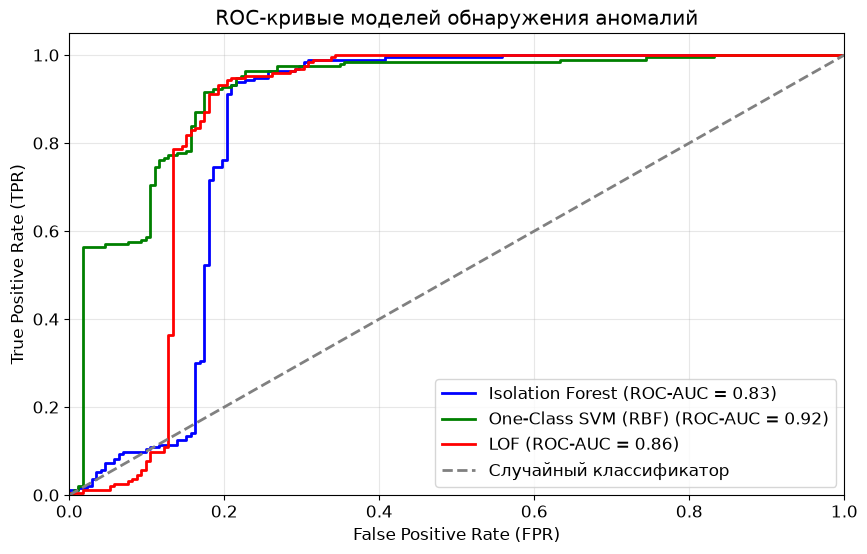

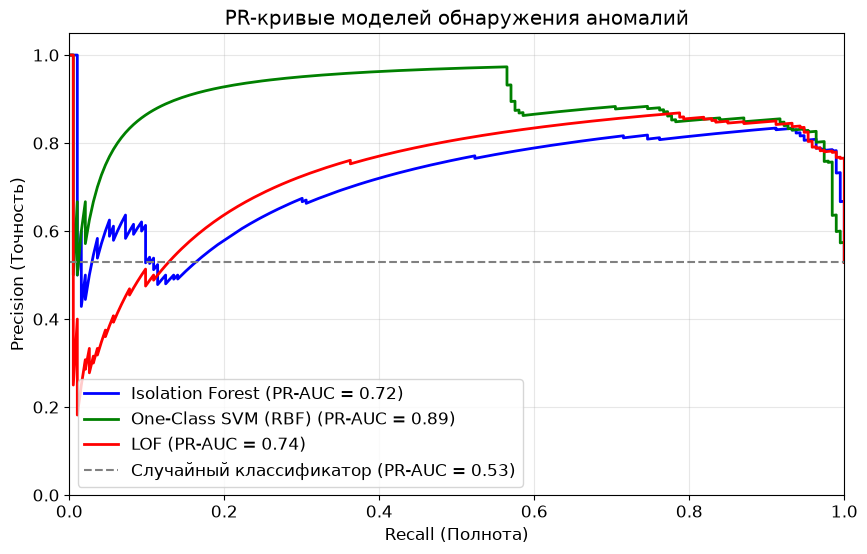

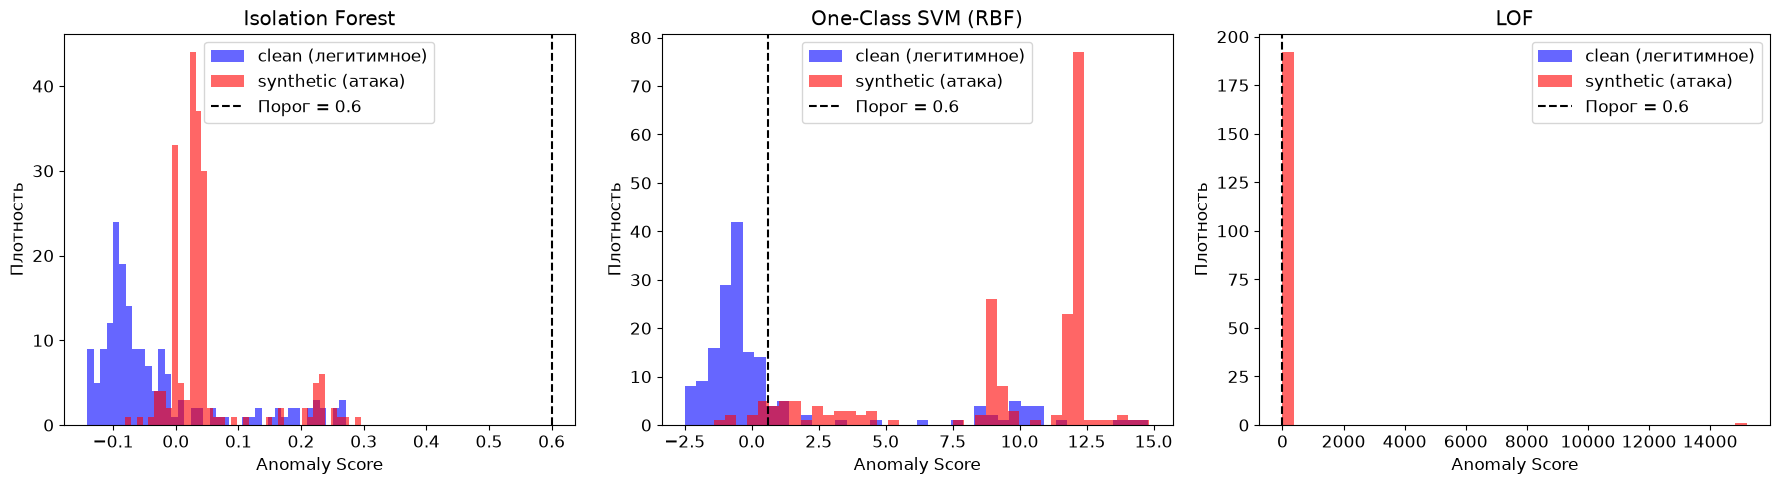

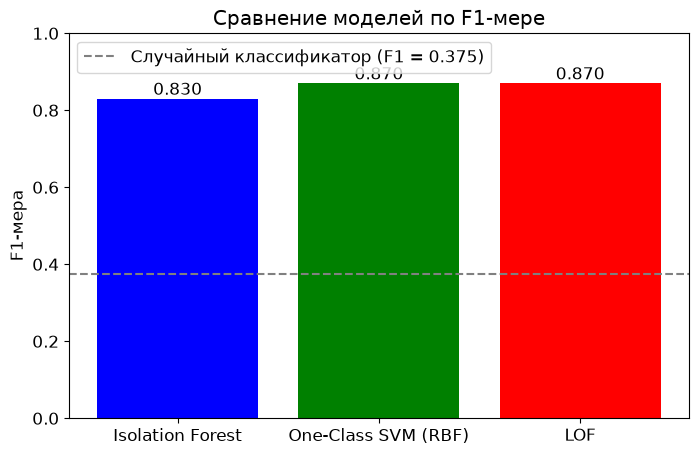

In [147]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
colors = {
    "Isolation Forest": "blue",
    "One-Class SVM (RBF)": "green",
    "LOF": "red"
}
plt.figure()
for model_name, data in plot_data.items():
    y_true = np.array(data["y_true"])
    scores = np.array(data["scores"])
    
    fpr, tpr, _ = roc_curve(y_true, scores)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, color=colors[model_name], lw=2,
             label=f'{model_name} (ROC-AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Случайный классификатор')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые моделей обнаружения аномалий')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

plt.figure()
for model_name, data in plot_data.items():
    y_true = np.array(data["y_true"])
    scores = np.array(data["scores"])
    
    precision, recall, _ = precision_recall_curve(y_true, scores)
    pr_auc = auc(recall, precision)
    
    plt.plot(recall, precision, color=colors[model_name], lw=2,
             label=f'{model_name} (PR-AUC = {pr_auc:.2f})')
baseline = sum(plot_data["Isolation Forest"]["y_true"]) / len(plot_data["Isolation Forest"]["y_true"])
plt.axhline(y=baseline, color='gray', linestyle='--', label=f'Случайный классификатор (PR-AUC = {baseline:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Полнота)')
plt.ylabel('Precision (Точность)')
plt.title('PR-кривые моделей обнаружения аномалий')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, data) in zip(axes, plot_data.items()):
    y_true = np.array(data["y_true"])
    scores = np.array(data["scores"])
    
    scores_clean = scores[y_true == 0]
    scores_synthetic = scores[y_true == 1]
    
    ax.hist(scores_clean, bins=40, alpha=0.6, color='blue', label='clean (легитимное)')
    ax.hist(scores_synthetic, bins=40, alpha=0.6, color='red', label='synthetic (атака)')
    

    ax.axvline(x=0.6, color='black', linestyle='--', label='Порог = 0.6')
    
    ax.set_title(model_name)
    ax.set_xlabel('Anomaly Score')
    ax.set_ylabel('Плотность')
    ax.legend()

plt.tight_layout()
plt.show()



df_res = pd.DataFrame(results)

df_res['F1_mean'] = df_res['F1'].apply(lambda x: float(x.split(' ± ')[0]))

plt.figure(figsize=(8, 5))
bars = plt.bar(df_res['Модель'], df_res['F1_mean'], color=['blue', 'green', 'red'])
plt.axhline(y=0.375, color='gray', linestyle='--', label='Случайный классификатор (F1 = 0.375)')
plt.ylabel('F1-мера')
plt.title('Сравнение моделей по F1-мере')
plt.ylim(0, 1.0)


for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.3f}', ha='center', va='bottom')

plt.legend()
plt.show()